In [1]:
# Load in the dataset
from astroNN.datasets import load_galaxy10
from tensorflow.keras import utils
import numpy as np

# To load images and labels (will download automatically at the first time)
# First time downloading location will be ~/.astroNN/datasets/
#images2, labels2 = load_galaxy10()
images, labels = load_galaxy10()
# To convert the labels to categorical 10 classes
#labels = utils.to_categorical(labels, 10)

# To convert to desirable type
#labels = labels2.astype(np.float32)
#images = images2.astype(np.float32)

/Users/mariepilskog/.astroNN/datasets/Galaxy10_DECals.h5 was found!


In [2]:
# Split into train and test
import numpy as np
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(np.arange(labels.shape[0]), test_size=0.2)
train_images, train_labels, test_images, test_labels = images[train_idx], labels[train_idx], images[test_idx], labels[test_idx]

In [3]:
def preprocess(imgs, size=16):
    """Downsample (N, 256, 256, 3) -> (N, size, size, 3) by block-averaging, then flatten."""
    N, H, W, C = imgs.shape
    f = H // size                                   # e.g. 256 // 16 = 16
    small = imgs.reshape(N, size, f, size, f, C).mean(axis=(2, 4))   # (N, size, size, 3)
    return small.reshape(N, -1) / 255.0             # (N, size*size*3)

x_train = preprocess(train_images, size = 128)         # 64*64*3 = 12288 features
x_test  = preprocess(test_images,  size = 128)
print(x_train.shape, x_test.shape)

(14188, 49152) (3548, 49152)


label: 1


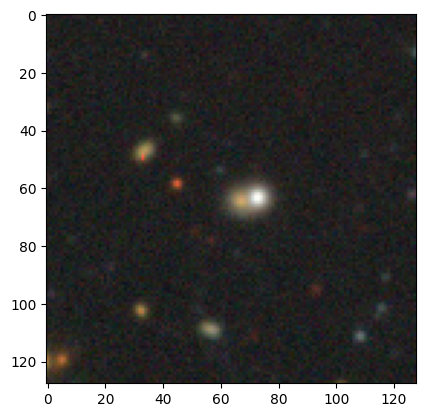

In [4]:
import matplotlib.pyplot as plt
image_2d = x_train[0].reshape(128,128,3)
plt.imshow(image_2d)

print("label:",train_labels[0])


In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from source.utils_classification import *
SEED = 2026
rng = np.random.default_rng(SEED)
plt.rcParams.update({'font.size': 13})

In [6]:
y_train = train_labels
y_test = test_labels

In [7]:
train_size = 10000  # choose any smaller size
indices = np.random.default_rng(2026).choice(
    len(x_train),
    size=train_size,
    replace=False
)
rng = np.random.default_rng(2026)
sub = rng.choice(len(x_train), 10000, replace=False)
small_x_train, small_y_train = x_train[sub], train_labels[sub]

# First tune architecture:
select_architecture = True

In [8]:

if select_architecture:
    architectures = [[50], [100], [100, 10], [100, 50]]
    gammas = np.linspace(0.001, 0.05, 3)
    best_parameters = None
    best_accuracy = 0 # choose small value since we want to values closest to 1
    save_parameters = []
    save_accuracy = []
    # Hard coding grid search
    for architecture in architectures:
        for gamma in gammas:
            t0 = time.time()
            cv_mean, cv_sd = cross_validate_neural_network(
                small_x_train, small_y_train, hidden_sizes=architecture,
                epochs=100, n_splits=3, lam=0.0, gamma=gamma
            )
            print(architecture, gamma, f"mean={cv_mean:.4f}", f"SD={cv_sd:.4f}", f"({round(time.time()-t0)} s)")
            save_parameters.append((architecture, gamma))
            save_accuracy.append(cv_mean)
            if cv_mean > best_accuracy:
                best_parameters = (architecture, gamma)
                best_accuracy = cv_mean
                threshold = cv_mean - cv_sd # Minus, since we want higher values

    save_accuracy = np.array(save_accuracy)
    within_one_sd = save_accuracy >= threshold
    eligible_indices = np.where(within_one_sd)[0]

    eligible_parameters = [save_parameters[i] for i in eligible_indices]
    
    for i in eligible_indices:
        print(f"Eligible parameters: {save_parameters[i]} " f"with accuracy {save_accuracy[i]:.4f} ")

    print(f"Best Architecture: {best_parameters[0]}; Best Learning Rate: {best_parameters[1]}")


Fold 1: 0.4361
Fold 2: 0.4236
Fold 3: 0.4017
[50] 0.001 mean=0.4205 SD=0.0100 (583 s)
Fold 1: 0.3623
Fold 2: 0.4071
Fold 3: 0.3183
[50] 0.025500000000000002 mean=0.3626 SD=0.0256 (567 s)
Fold 1: 0.2762
Fold 2: 0.2247
Fold 3: 0.2451
[50] 0.05 mean=0.2487 SD=0.0150 (540 s)
Fold 1: 0.4496
Fold 2: 0.4272
Fold 3: 0.4260
[100] 0.001 mean=0.4343 SD=0.0077 (1115 s)
Fold 1: 0.4982
Fold 2: 0.4596
Fold 3: 0.4047
[100] 0.025500000000000002 mean=0.4542 SD=0.0271 (1160 s)
Fold 1: 0.3071
Fold 2: 0.2742
Fold 3: 0.3276
[100] 0.05 mean=0.3030 SD=0.0156 (2553 s)
Fold 1: 0.4025
Fold 2: 0.3591
Fold 3: 0.4125
[100, 10] 0.001 mean=0.3914 SD=0.0164 (1287 s)
Fold 1: 0.4220
Fold 2: 0.5305
Fold 3: 0.1488
[100, 10] 0.025500000000000002 mean=0.3671 SD=0.1135 (1150 s)
Fold 1: 0.1488
Fold 2: 0.5026
Fold 3: 0.1488
[100, 10] 0.05 mean=0.2667 SD=0.1179 (1130 s)
Fold 1: 0.4283
Fold 2: 0.4488
Fold 3: 0.4311
[100, 50] 0.001 mean=0.4361 SD=0.0064 (1157 s)
Fold 1: 0.5735
Fold 2: 0.5197
Fold 3: 0.5446
[100, 50] 0.02550000000

In [ ]:
best_architecture = [100, 50]

select_learning_rate_norm = False
# Selected using smaller training set (10000):
# Change between plain, adam and rms here.
if select_learning_rate_norm:
    gammas = np.linspace(0.01, 0.6, 5)
    lambda_values = np.linspace(0, 1e-3, 5)
    best_parameters = None
    best_accuracy = 0
    save_accuracy = []
    save_parameters = []
    for gamma in gammas:
        for lam in lambda_values:
            t0 = time.time()
            cv_mean, cv_sd = cross_validate_neural_network(
                small_x_train, small_y_train, hidden_sizes=best_architecture,
                epochs=50, n_splits=3, lam=lam, norm="l2", gamma=gamma, method="plain"
            )
            print(gamma, lam, f"mean={cv_mean:.4f}", f"SD={cv_sd:.4f}", f"({round(time.time()-t0)} s)")

            save_accuracy.append(cv_mean)
            save_parameters.append((gamma, lam))
            if best_accuracy < cv_mean:
                best_parameters = (gamma, lam)
                best_accuracy = cv_mean
                threshold = cv_mean - cv_sd
    
    save_accuracy = np.array(save_accuracy)
    within_one_sd = save_accuracy >= threshold
    eligible_indices = np.where(within_one_sd)[0]

    eligible_parameters = [save_parameters[i] for i in eligible_indices]
    
    for i in eligible_indices:
        print(f"Eligible parameters: {save_parameters[i]} " f"with accuracy {save_accuracy[i]:.4f} ")

    print(f"Best Learning Rate: {best_parameters[0]}; Best L2 penalty parameter: {best_parameters[1]}")
    